In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from sklearn.metrics import accuracy_score
from collections import Counter
from datasets import load_dataset
import random
import math
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('dark_background')
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: cpu
PyTorch version: 2.11.0+cpu


In [2]:
# Entity lists
companies = ['Google', 'Microsoft', 'Apple', 'Amazon', 'Facebook', 'Alaraby', 'Noon',
             'IBM', 'Intel', 'Oracle', 'Samsung', 'Sony', 'Toyota', 'Nike', 'Adidas']
people = ["Ali", "Mona", "Ahmed", "Samira", "Hassan", "Layla", "Youssuf", "Nadia",
          "Omar", "Reem", "Khalid", "Amira", "Mustafa", "Fatema", "Tariq"]

templates_ner = [
    '{person} works at {company}',
    '{company} hired {person} last month',
    '{person} is the CEO of {company}',
    'The meeting with {person} at {company} was productive',
    '{company} announced a new product by {person}',
    '{person} and {person} joined {company}',
    '{company} and {company} are competitors',
    '{person} left {company} for {company}',
]


def generate_ner_sentence():
    template = random.choice(templates_ner)
    sentence = template
    while '{person}' in sentence:
        sentence = sentence.replace('{person}', random.choice(people), 1)
    while '{company}' in sentence:
        sentence = sentence.replace('{company}', random.choice(companies), 1)
    words = sentence.lower().split()
    # Labels: 0=Other, 1=Person, 2=Company
    labels = []
    for word in words:
        if word.lower() in [p.lower() for p in people]:
            labels.append(1)
        elif word.lower() in [c.lower() for c in companies]:
            labels.append(2)
        else:
            labels.append(0)
    return words, labels


# Generate 2000 sentences
random.seed(42)
ner_sentences = []
ner_labels = []
for _ in range(2000):
    words, labels = generate_ner_sentence()
    ner_sentences.append(words)
    ner_labels.append(labels)

# Split
split1 = int(0.8 * len(ner_sentences))
split2 = int(0.9 * len(ner_sentences))
train_ner_sent = ner_sentences[:split1]
train_ner_lab = ner_labels[:split1]
val_ner_sent = ner_sentences[split1:split2]
val_ner_lab = ner_labels[split1:split2]
test_ner_sent = ner_sentences[split2:]
test_ner_lab = ner_labels[split2:]

print(f'Generated {len(ner_sentences)} NER sentences')
print(f'Train: {len(train_ner_sent)}, Val: {len(val_ner_sent)}, Test: {len(test_ner_sent)}')
print(f'\nSample: {", ".join(train_ner_sent[0])}')
print(f'Labels: {train_ner_lab[0]} (0=O, 1=Person, 2=Company)')

Generated 2000 NER sentences
Train: 1600, Val: 200, Test: 200

Sample: sony, hired, ali, last, month
Labels: [2, 0, 1, 0, 0] (0=O, 1=Person, 2=Company)


##TODO 1: Build Vocabulary and Dataset

In [3]:
ner_vocab = {'<PAD>': 0, '<UNK>': 1}
ner_word_counts = Counter()

for sentence in train_ner_sent:
    ner_word_counts.update(sentence)

for word, count in ner_word_counts.items():
    if count >= 2 and word not in ner_vocab:
        ner_vocab[word] = len(ner_vocab)


class NERDataset(Dataset):
    """Dataset for Company/Person NER (Many-to-Many)"""

    def __init__(self, sentences, labels, vocab):
        self.sentences = sentences
        self.labels = labels
        self.vocab = vocab

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, idx):
        word_ids = [self.vocab.get(word, self.vocab['<UNK>']) for word in self.sentences[idx]]
        labels = self.labels[idx]
        return torch.tensor(word_ids, dtype=torch.long), torch.tensor(labels, dtype=torch.long)


def ner_collate_fn(batch):
    sentences, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in sentences])
    padded_sentences = pad_sequence(sentences, batch_first=True, padding_value=ner_vocab['<PAD>'])
    padded_labels = pad_sequence(labels, batch_first=True, padding_value=-1)
    return padded_sentences, padded_labels, lengths


train_ner_dataset = NERDataset(train_ner_sent, train_ner_lab, ner_vocab)
val_ner_dataset = NERDataset(val_ner_sent, val_ner_lab, ner_vocab)
test_ner_dataset = NERDataset(test_ner_sent, test_ner_lab, ner_vocab)

train_ner_loader = DataLoader(train_ner_dataset, batch_size=32, shuffle=True, collate_fn=ner_collate_fn)
val_ner_loader = DataLoader(val_ner_dataset, batch_size=32, shuffle=False, collate_fn=ner_collate_fn)
test_ner_loader = DataLoader(test_ner_dataset, batch_size=32, shuffle=False, collate_fn=ner_collate_fn)

print(f'NER Vocabulary size: {len(ner_vocab)}')
print(f'Train batches: {len(train_ner_loader)}')

NER Vocabulary size: 56
Train batches: 50


##TODO 2: Implement BiLSTM + Attention for NER

In [4]:
class BiLSTMAttentionNER(nn.Module):
    """BiLSTM with Self-Attention for Many-to-Many sequence labeling (NER)"""

    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )
        self.attn_proj = nn.Linear(hidden_dim * 2, hidden_dim * 2)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 4, output_dim)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))

        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        lstm_out, _ = self.lstm(packed)
        lstm_out, _ = torch.nn.utils.rnn.pad_packed_sequence(
            lstm_out, batch_first=True, total_length=x.size(1)
        )

        queries = self.attn_proj(lstm_out)
        attn_scores = torch.bmm(queries, lstm_out.transpose(1, 2)) / math.sqrt(lstm_out.size(-1))

        max_len = x.size(1)
        key_mask = torch.arange(max_len, device=x.device).unsqueeze(0) < lengths.unsqueeze(1)  # (batch, seq_len)
        attn_scores = attn_scores.masked_fill(~key_mask.unsqueeze(1), -1e9)

        attn_weights = F.softmax(attn_scores, dim=-1)
        context = torch.bmm(attn_weights, lstm_out)

        combined = torch.cat([lstm_out, context], dim=-1)
        logits = self.fc(self.dropout(combined))
        return logits


print('BiLSTM + Attention NER model defined!')

BiLSTM + Attention NER model defined!


##TODO 3: Implement Transformer for NER

In [10]:
class PositionalEncoding(nn.Module):
    """Standard sinusoidal positional encoding"""
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        # x shape: [batch_size, seq_len, d_model]
        return x + self.pe[:, :x.size(1)]

class TransformerNER(nn.Module):
    """Transformer Encoder for Many-to-Many NER"""

    def __init__(self, vocab_size, embedding_dim, nhead=4, num_layers=2, output_dim=3, dim_feedforward=256):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.pos_encoder = PositionalEncoding(embedding_dim)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=0.1,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(embedding_dim, output_dim)

    def forward(self, x, lengths):
        max_len = x.size(1)
        padding_mask = torch.arange(max_len, device=x.device).unsqueeze(0) >= lengths.unsqueeze(1)

        embedded = self.embedding(x)
        embedded = self.pos_encoder(embedded)

        output = self.transformer_encoder(embedded, src_key_padding_mask=padding_mask)

        logits = self.fc(self.dropout(output))
        return logits

print('Transformer NER model and PositionalEncoding defined!')

Transformer NER model and PositionalEncoding defined!


In [11]:
def train_ner_model(model, train_loader, epochs=15, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=-1)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for sentences, labels, lengths in train_loader:
            sentences, labels = sentences.to(device), labels.to(device)
            lengths = lengths.to(device)
            optimizer.zero_grad()
            predictions = model(sentences, lengths)
            predictions = predictions.view(-1, 3)
            labels = labels.view(-1)
            loss = criterion(predictions, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}')
    return losses


def evaluate_ner_model(model, test_loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for sentences, labels, lengths in test_loader:
            sentences = sentences.to(device)
            lengths = lengths.to(device)
            predictions = model(sentences, lengths)
            predictions = torch.argmax(predictions, dim=2)
            for i in range(len(sentences)):
                length = lengths[i].item()
                all_preds.extend(predictions[i, :length].cpu().numpy())
                all_labels.extend(labels[i, :length].numpy())
    accuracy = accuracy_score(all_labels, all_preds)
    return accuracy


print('Training functions ready!')

Training functions ready!


In [12]:
# Create embedding matrix for NER
ner_embedding_matrix = np.random.randn(len(ner_vocab), 100).astype('float32') * 0.01
ner_embedding_matrix[ner_vocab['<PAD>']] = np.zeros(100)

# Safely check if glove_vectors exists
if 'glove_vectors' in globals():
    for word, idx in ner_vocab.items():
        if word in glove_vectors:
            ner_embedding_matrix[idx] = glove_vectors[word]
else:
    print("glove_vectors not found. Using randomly initialized embeddings.")

# Train BiLSTM + Attention
print('='*60)
print('Training BiLSTM + Attention NER...')
print('='*60)
bilstm_attn_ner = BiLSTMAttentionNER(len(ner_vocab), 100, 128, 3)
bilstm_attn_ner.embedding.weight.data.copy_(torch.from_numpy(ner_embedding_matrix))
bilstm_losses = train_ner_model(bilstm_attn_ner, train_ner_loader, epochs=15)
bilstm_acc = evaluate_ner_model(bilstm_attn_ner, test_ner_loader)
print(f'\nBiLSTM + Attention Accuracy: {bilstm_acc:.4f}\n')

# Train Transformer
print('='*60)
print('Training Transformer NER...')
print('='*60)
transformer_ner = TransformerNER(len(ner_vocab), 100, 4, 2, 3)
transformer_ner.embedding.weight.data.copy_(torch.from_numpy(ner_embedding_matrix))
transformer_losses = train_ner_model(transformer_ner, train_ner_loader, epochs=15, lr=0.0005)
transformer_acc = evaluate_ner_model(transformer_ner, test_ner_loader)
print(f'\nTransformer Accuracy: {transformer_acc:.4f}\n')

glove_vectors not found. Using randomly initialized embeddings.
Training BiLSTM + Attention NER...
Epoch 1/15, Loss: 0.8906
Epoch 2/15, Loss: 0.1869
Epoch 3/15, Loss: 0.0014
Epoch 4/15, Loss: 0.0005
Epoch 5/15, Loss: 0.0003
Epoch 6/15, Loss: 0.0002
Epoch 7/15, Loss: 0.0002
Epoch 8/15, Loss: 0.0001
Epoch 9/15, Loss: 0.0001
Epoch 10/15, Loss: 0.0001
Epoch 11/15, Loss: 0.0001
Epoch 12/15, Loss: 0.0001
Epoch 13/15, Loss: 0.0001
Epoch 14/15, Loss: 0.0001
Epoch 15/15, Loss: 0.0000

BiLSTM + Attention Accuracy: 1.0000

Training Transformer NER...
Epoch 1/15, Loss: 0.7974
Epoch 2/15, Loss: 0.1521
Epoch 3/15, Loss: 0.0046
Epoch 4/15, Loss: 0.0019
Epoch 5/15, Loss: 0.0015
Epoch 6/15, Loss: 0.0011
Epoch 7/15, Loss: 0.0008
Epoch 8/15, Loss: 0.0007
Epoch 9/15, Loss: 0.0006
Epoch 10/15, Loss: 0.0005
Epoch 11/15, Loss: 0.0005
Epoch 12/15, Loss: 0.0004
Epoch 13/15, Loss: 0.0004
Epoch 14/15, Loss: 0.0003
Epoch 15/15, Loss: 0.0003

Transformer Accuracy: 1.0000



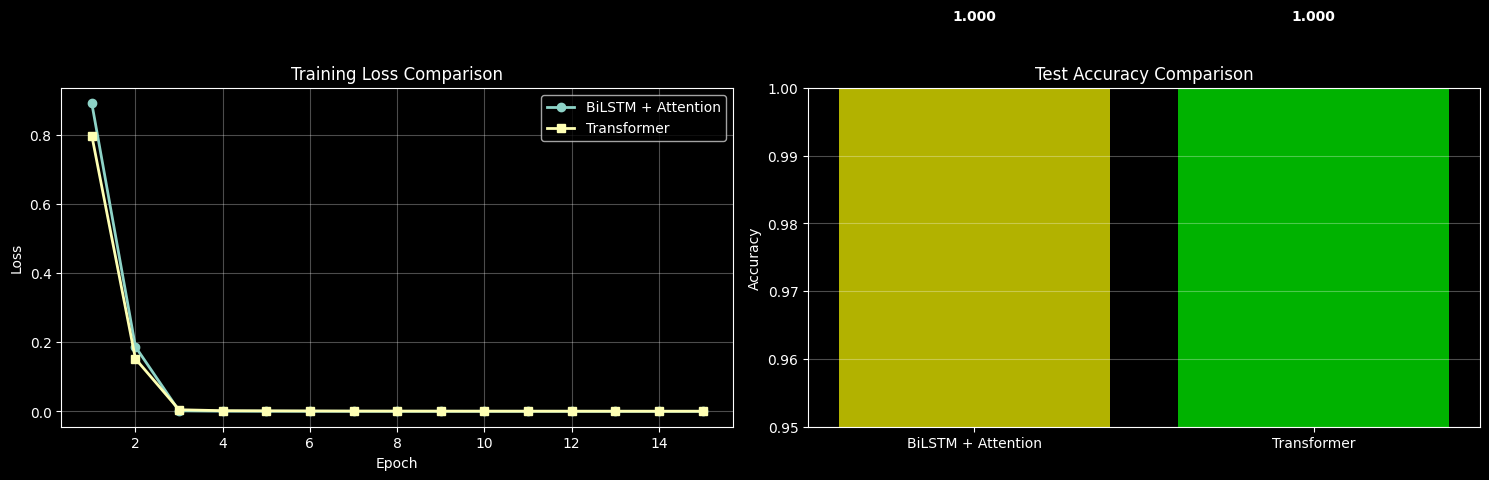

NER RESULTS
BiLSTM + Attention        Accuracy: 1.0000
Transformer               Accuracy: 1.0000


In [13]:
# Visualize comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(range(1, 16), bilstm_losses, marker='o', label='BiLSTM + Attention', linewidth=2)
ax1.plot(range(1, 16), transformer_losses, marker='s', label='Transformer', linewidth=2)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training Loss Comparison')
ax1.legend()
ax1.grid(alpha=0.3)

models = ['BiLSTM + Attention', 'Transformer']
accuracies = [bilstm_acc, transformer_acc]
colors = ['yellow', 'lime']
ax2.bar(models, accuracies, color=colors, alpha=0.7)
ax2.set_ylabel('Accuracy')
ax2.set_title('Test Accuracy Comparison')
ax2.set_ylim([min(accuracies) - 0.05, 1.0])
ax2.grid(alpha=0.3, axis='y')
for i, v in enumerate(accuracies):
    ax2.text(i, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print('='*60)
print('NER RESULTS')
print('='*60)
for model, acc in zip(models, accuracies):
    print(f'{model:25s} Accuracy: {acc:.4f}')
print('='*60)